# Grid Martingale Backtest — Exness Standard Cent + $0.04/lot Markup

Tick-accurate backtest with:
- Entry at bar open (first trade of basket)
- Grid adds on every tick
- Dynamic TP, trailing SL, VirtualBalance risk management
- $0.04 synthetic markup per 0.01 cent lot
- Hourly equity / margin / drawdown progress
- No look-forward bias

In [5]:
# ================================================================
# Grid Martingale Backtest — No synthetic markup
# Only the bid-ask spread from the tick data is charged
# ================================================================

from dataclasses import dataclass, field
from typing import List, Optional
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
import time


# ================================================================
# 1) CONFIG
# ================================================================

@dataclass
class Config:
    # --- Simulation window ---
    N_hours:          Optional[float] = 1.0
    start_hour:       float = 0.0

    # --- MT4 EA inputs ---
    first_lot:        float = 0.01
    distance_pips:    float = 10.0
    max_orders:       int   = 100
    tp_in_money:      float = 0.004    # 4 pips on 0.01 cent lot = $0.004 USD = 0.4 USC
    lot_multiplier:   float = 2.0

    # --- Trailing stop ---
    use_trailing:     bool  = True
    tp_start:         float = 2.0
    tp_move:          float = 4.0

    # --- Risk management ---
    amount_to_risk:   float = 100.0
    profit_to_fix:    float = 10.0

    # --- Exness Standard Cent specifics ---
    pip_size:         float = 0.0001
    contract_size:    float = 1_000.0
    min_lot:          float = 0.01
    lot_step:         float = 0.01
    leverage:         int   = 500

    # (no markup — the tick data's bid/ask is the only cost)


# ================================================================
# 2) DATA STRUCTURES
# ================================================================

@dataclass
class Position:
    ticket:     int
    side:       int
    entry_idx:  int
    entry_px:   float
    lots:       float
    entry_time: object = None
    sl:         float = 0.0

    def unrealized(self, bid, ask, cfg):
        if self.side == +1:
            return (bid - self.entry_px) * self.lots * cfg.contract_size
        return (self.entry_px - ask) * self.lots * cfg.contract_size


@dataclass
class Trade:
    ticket:     int
    side:       int
    entry_idx:  int
    entry_px:   float
    exit_idx:   int
    exit_px:    float
    lots:       float
    pnl:        float
    entry_time: object = None
    exit_time:  object = None
    reason:     str = ""


@dataclass
class BacktestResult:
    trades:         List[Trade] = field(default_factory=list)
    equity:         List[float] = field(default_factory=list)
    equity_times:   List = field(default_factory=list)
    position_sizes: List[float] = field(default_factory=list)
    balance:        float = 0.0
    max_dd:         float = 0.0
    resets:         int = 0
    stop_outs:      int = 0
    hourly_records: List[dict] = field(default_factory=list)


def _round_lot(lot, cfg):
    steps = round(lot / cfg.lot_step)
    return max(cfg.min_lot, steps * cfg.lot_step)


# ================================================================
# 3) LOAD RAW TICKS ONCE
# ================================================================

FILE_PATHS = [
    r"D:\Iskander\archive\USDCHF_202002_ticks.csv",
    r"D:\Iskander\archive\USDCHF_202003_ticks.csv",
    r"D:\Iskander\archive\USDCHF_202004_ticks.csv",
    r"D:\Iskander\archive\USDCHF_202005_ticks.csv",
]

def load_all_tick_data(file_paths):
    all_dfs = []
    for fp in file_paths:
        print(f"   Loading {fp}...")
        d = pd.read_csv(fp, parse_dates=['DateTime'],
                        usecols=['DateTime', 'Bid', 'Ask', 'Volume'])
        all_dfs.append(d)
    out = pd.concat(all_dfs, ignore_index=True)
    out = out.sort_values('DateTime').reset_index(drop=True)
    return out


print("Loading ALL tick data into memory (once)...")
t_load = time.time()
tick_df = load_all_tick_data(FILE_PATHS)
DATA_START = tick_df['DateTime'].iloc[0]
DATA_END   = tick_df['DateTime'].iloc[-1]
print(f"   Total ticks: {len(tick_df):,}")
print(f"   Data range : {DATA_START} → {DATA_END}")
print(f"   Loaded in  : {time.time() - t_load:.1f}s")


# ================================================================
# 4) BACKTEST ENGINE (no markup)
# ================================================================

def backtest_ticks(bars, cfg, starting_balance=100.0):
    """
    Tick-accurate backtest. No synthetic markup.
    The bid-ask spread is only what the tick data says it is:
      - BUY entry  fills at Ask
      - SELL entry fills at Bid
      - BUY exit   fills at Bid
      - SELL exit  fills at Ask
    """
    res = BacktestResult()
    balance = starting_balance
    positions: List[Position] = []
    res.equity.append(balance)
    res.equity_times.append(bars[0]['time'])
    res.position_sizes.append(0.0)

    step = cfg.distance_pips * cfg.pip_size
    n = len(bars)
    peak = starting_balance

    initial_balance = starting_balance
    closed_profit = 0.0
    next_ticket = 1

    # Hourly tracking
    current_hour = None
    hourly_balance = starting_balance
    hourly_equity = starting_balance
    hourly_pos_lots = 0.0
    hourly_margin = 0.0
    hourly_peak = starting_balance

    last_processed_idx = None

    for i in range(2, n):
        last_processed_idx = i
        bar = bars[i]
        ticks = bar.get('ticks') or [(bar['time'], bar['open'], bar['open'])]
        signal_before = bars[i-2]['close']
        signal_last   = bars[i-1]['close']
        first_tick = True

        for (ts, bid, ask) in ticks:
            # ---- A) basket state ----
            open_drawdown = 0.0
            basket_profit = 0.0
            total_lots = 0.0
            for p in positions:
                pl = p.unrealized(bid, ask, cfg)
                basket_profit += pl
                total_lots += p.lots
                if pl < 0:
                    open_drawdown += abs(pl)

            # ---- B) risk mgmt ----
            virtual_balance = initial_balance + closed_profit - open_drawdown
            risk_exit = (
                virtual_balance <= initial_balance - cfg.amount_to_risk or
                virtual_balance >= initial_balance + cfg.profit_to_fix
            )
            if risk_exit and positions:
                reason = "RISK_LOSS" if virtual_balance <= initial_balance - cfg.amount_to_risk else "RISK_PROFIT"
                for p in positions:
                    pnl = p.unrealized(bid, ask, cfg)
                    balance += pnl
                    closed_profit += pnl
                    res.trades.append(Trade(
                        ticket=p.ticket, side=p.side,
                        entry_idx=p.entry_idx, entry_px=p.entry_px,
                        exit_idx=i, exit_px=(bid if p.side == +1 else ask),
                        lots=p.lots, pnl=pnl,
                        entry_time=p.entry_time, exit_time=ts,
                        reason=reason,
                    ))
                positions.clear()
                res.resets += 1
                initial_balance = virtual_balance
                closed_profit = 0.0
                res.equity.append(balance)
                res.equity_times.append(ts)
                res.position_sizes.append(0.0)
                continue

            # ---- C) 0% stop out ----
            if positions:
                equity = balance + basket_profit
                used_margin = sum(p.lots * cfg.contract_size / cfg.leverage for p in positions)
                margin_level = (equity / used_margin * 100) if used_margin > 0 else float('inf')
                if margin_level <= 0.0 and used_margin > 0:
                    for p in sorted(positions, key=lambda x: x.unrealized(bid, ask, cfg)):
                        pnl = p.unrealized(bid, ask, cfg)
                        balance += pnl
                        closed_profit += pnl
                        res.trades.append(Trade(
                            ticket=p.ticket, side=p.side,
                            entry_idx=p.entry_idx, entry_px=p.entry_px,
                            exit_idx=i, exit_px=(bid if p.side == +1 else ask),
                            lots=p.lots, pnl=pnl,
                            entry_time=p.entry_time, exit_time=ts,
                            reason="STOP_OUT",
                        ))
                    positions.clear()
                    res.stop_outs += 1
                    res.equity.append(balance)
                    res.equity_times.append(ts)
                    res.position_sizes.append(0.0)
                    continue

            # ---- D) trailing SL ----
            if cfg.use_trailing and positions:
                for p in positions:
                    if p.side == +1:
                        pp = (bid - p.entry_px) / cfg.pip_size
                        if pp >= cfg.tp_start:
                            steps = int((pp - cfg.tp_start) // cfg.tp_move)
                            new_sl = round(p.entry_px + (cfg.tp_start + steps * cfg.tp_move) * cfg.pip_size, 5)
                            if new_sl > p.sl + cfg.pip_size:
                                p.sl = new_sl
                    else:
                        pp = (p.entry_px - ask) / cfg.pip_size
                        if pp >= cfg.tp_start:
                            steps = int((pp - cfg.tp_start) // cfg.tp_move)
                            new_sl = round(p.entry_px - (cfg.tp_start + steps * cfg.tp_move) * cfg.pip_size, 5)
                            if new_sl < p.sl - cfg.pip_size or p.sl == 0:
                                p.sl = new_sl

                still_open = []
                for p in positions:
                    hit = (p.side == +1 and p.sl > 0 and bid <= p.sl) or \
                          (p.side == -1 and p.sl > 0 and ask >= p.sl)
                    if hit:
                        pnl = p.unrealized(bid, ask, cfg)
                        balance += pnl
                        closed_profit += pnl
                        res.trades.append(Trade(
                            ticket=p.ticket, side=p.side,
                            entry_idx=p.entry_idx, entry_px=p.entry_px,
                            exit_idx=i, exit_px=p.sl,
                            lots=p.lots, pnl=pnl,
                            entry_time=p.entry_time, exit_time=ts,
                            reason="TRAILING_SL",
                        ))
                    else:
                        still_open.append(p)
                positions = still_open

            # ---- E) dynamic TP ----
            if positions:
                basket_profit = sum(p.unrealized(bid, ask, cfg) for p in positions)
                total_lots = sum(p.lots for p in positions)
                if total_lots > 0:
                    dynamic_tp = cfg.tp_in_money * (total_lots / cfg.first_lot)
                    if basket_profit >= dynamic_tp:
                        for p in positions:
                            pnl = p.unrealized(bid, ask, cfg)
                            balance += pnl
                            closed_profit += pnl
                            res.trades.append(Trade(
                                ticket=p.ticket, side=p.side,
                                entry_idx=p.entry_idx, entry_px=p.entry_px,
                                exit_idx=i, exit_px=(bid if p.side == +1 else ask),
                                lots=p.lots, pnl=pnl,
                                entry_time=p.entry_time, exit_time=ts,
                                reason="TAKE_PROFIT",
                            ))
                        positions.clear()
                        res.equity.append(balance)
                        res.equity_times.append(ts)
                        res.position_sizes.append(0.0)
                        continue

            # ---- F) first trade (bar open = first tick) ----
            if first_tick and not positions:
                margin_needed = cfg.first_lot * cfg.contract_size / cfg.leverage
                if balance > margin_needed:
                    if signal_before < signal_last:
                        positions.append(Position(
                            ticket=next_ticket, side=+1, entry_idx=i,
                            entry_px=ask, lots=cfg.first_lot, entry_time=ts
                        ))
                        next_ticket += 1
                    elif signal_before > signal_last:
                        positions.append(Position(
                            ticket=next_ticket, side=-1, entry_idx=i,
                            entry_px=bid, lots=cfg.first_lot, entry_time=ts
                        ))
                        next_ticket += 1

            # ---- G) grid add (on ticks) ----
            if positions and not first_tick:
                if len(positions) < cfg.max_orders:
                    anchor = positions[-1]
                    next_lot = _round_lot(anchor.lots * cfg.lot_multiplier, cfg)
                    margin_needed = next_lot * cfg.contract_size / cfg.leverage
                    if balance > margin_needed:
                        if anchor.side == +1 and ask <= anchor.entry_px - step:
                            positions.append(Position(
                                ticket=next_ticket, side=+1, entry_idx=i,
                                entry_px=ask, lots=next_lot, entry_time=ts
                            ))
                            next_ticket += 1
                        elif anchor.side == -1 and bid >= anchor.entry_px + step:
                            positions.append(Position(
                                ticket=next_ticket, side=-1, entry_idx=i,
                                entry_px=bid, lots=next_lot, entry_time=ts
                            ))
                            next_ticket += 1

            first_tick = False

            # ---- H) equity/DD ----
            floating = sum(p.unrealized(bid, ask, cfg) for p in positions)
            eq = balance + floating
            res.equity.append(eq)
            res.equity_times.append(ts)
            res.position_sizes.append(sum(p.lots for p in positions))
            if eq > peak:
                peak = eq
            dd = (peak - eq) / peak if peak > 0 else 0.0
            if dd > res.max_dd:
                res.max_dd = dd

            # ---- I) hourly snapshot ----
            tick_hour = ts.replace(minute=0, second=0, microsecond=0)
            if current_hour is None:
                current_hour = tick_hour
            if tick_hour != current_hour:
                res.hourly_records.append({
                    'hour':         current_hour,
                    'balance':      hourly_balance,
                    'equity':       hourly_equity,
                    'total_lots':   hourly_pos_lots,
                    'margin_used':  hourly_margin,
                    'drawdown_pct': (hourly_peak - hourly_equity) / hourly_peak * 100
                                    if hourly_peak > 0 else 0.0,
                })
                current_hour = tick_hour
            hourly_balance  = balance
            hourly_equity   = eq
            hourly_pos_lots = sum(p.lots for p in positions)
            hourly_margin   = sum(p.lots * cfg.contract_size / cfg.leverage for p in positions)
            if eq > hourly_peak:
                hourly_peak = eq

    # Flush final hour
    if current_hour is not None:
        res.hourly_records.append({
            'hour':         current_hour,
            'balance':      hourly_balance,
            'equity':       hourly_equity,
            'total_lots':   hourly_pos_lots,
            'margin_used':  hourly_margin,
            'drawdown_pct': (hourly_peak - hourly_equity) / hourly_peak * 100
                            if hourly_peak > 0 else 0.0,
        })

    # Force close remaining — use LAST bar actually processed
    if positions:
        if last_processed_idx is None:
            last_processed_idx = 2
        last_bar = bars[last_processed_idx]
        last_ticks = last_bar.get('ticks') or [
            (last_bar['time'], last_bar['close'], last_bar['close'])
        ]
        _, last_bid, last_ask = last_ticks[-1]
        for p in positions:
            pnl = p.unrealized(last_bid, last_ask, cfg)
            balance += pnl
            closed_profit += pnl
            res.trades.append(Trade(
                ticket=p.ticket, side=p.side,
                entry_idx=p.entry_idx, entry_px=p.entry_px,
                exit_idx=last_processed_idx,
                exit_px=(last_bid if p.side == +1 else last_ask),
                lots=p.lots, pnl=pnl,
                entry_time=p.entry_time, exit_time=last_bar['time'],
                reason="FORCE_CLOSE_AT_WINDOW_END",
            ))
        positions.clear()

    res.balance = balance
    return res


# ================================================================
# 5) WINDOW BUILDER — slice ticks, build candles, build bars
# ================================================================

def build_window(cfg, tick_df, data_start):
    t0 = time.time()
    window_start = data_start + pd.Timedelta(hours=cfg.start_hour)
    if cfg.N_hours is not None:
        window_end = window_start + pd.Timedelta(hours=cfg.N_hours)
    else:
        window_end = tick_df['DateTime'].iloc[-1]

    mask = (tick_df['DateTime'] >= window_start) & (tick_df['DateTime'] <= window_end)
    ticks_win = tick_df.loc[mask].copy()
    if len(ticks_win) == 0:
        return [], None, window_start, window_end

    ticks_win['Minute'] = ticks_win['DateTime'].dt.floor('1min')

    def compute_ohlc_with_spread(group):
        return pd.Series({
            'Bid_Open':   group.iloc[0]['Bid'],
            'Bid_High':   group['Bid'].max(),
            'Bid_Low':    group['Bid'].min(),
            'Bid_Close':  group.iloc[-1]['Bid'],
            'Ask_Open':   group.iloc[0]['Ask'],
            'Ask_High':   group['Ask'].max(),
            'Ask_Low':    group['Ask'].min(),
            'Ask_Close':  group.iloc[-1]['Ask'],
            'Volume':     group['Volume'].sum(),
            'Avg_Spread': (group['Ask'] - group['Bid']).mean(),
            'Ticks':      list(zip(group['DateTime'], group['Bid'], group['Ask'])),
        })

    candles_win = ticks_win.groupby('Minute').apply(compute_ohlc_with_spread).reset_index()
    candles_win = candles_win.sort_values('Minute').reset_index(drop=True)

    bars = []
    for row in candles_win.itertuples(index=False):
        bars.append({
            'time':  row.Minute,
            'open':  row.Bid_Open,
            'high':  row.Bid_High,
            'low':   row.Bid_Low,
            'close': row.Bid_Close,
            'ticks': row.Ticks,
        })

    print(f"   Ticks in window : {len(ticks_win):,}")
    print(f"   Candles built   : {len(candles_win):,}")
    print(f"   Build time      : {time.time() - t0:.2f}s")
    return bars, candles_win, window_start, window_end


print("\nSetup complete. Run the next cell to simulate.")

Loading ALL tick data into memory (once)...
   Loading D:\Iskander\archive\USDCHF_202002_ticks.csv...
   Loading D:\Iskander\archive\USDCHF_202003_ticks.csv...
   Loading D:\Iskander\archive\USDCHF_202004_ticks.csv...
   Loading D:\Iskander\archive\USDCHF_202005_ticks.csv...
   Total ticks: 8,539,427
   Data range : 2020-02-02 17:00:14.503000 → 2020-05-29 16:59:53.963000
   Loaded in  : 21.5s

Setup complete. Run the next cell to simulate.



=== Building window: start_hour=0.0, N_hours=224.0 ===


C:\Users\user\AppData\Local\Temp\ipykernel_15584\436554302.py:461: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  candles_win = ticks_win.groupby('Minute').apply(compute_ohlc_with_spread).reset_index()


   Ticks in window : 367,334
   Candles built   : 10,444
   Build time      : 16.36s
Window            : 2020-02-02 17:00:14.503000 → 2020-02-12 01:00:14.503000
Starting balance  : $100.0000
Final balance     : $112.0875
Return            : 12.0875%
Max drawdown      : 54.0362%
Total trades      : 122
Risk resets       : 1
Stop outs         : 0

TRADE LOG:
 ticket  side  lots              entry_time entry_px               exit_time exit_px        pnl                    reason
      2 SHORT  0.02 2020-02-02 19:33:46.154  0.96419 2020-02-02 20:23:53.248 0.96399  +0.004000               TRAILING_SL
      3 SHORT  0.02 2020-02-02 20:33:38.975  0.96420 2020-02-02 21:17:22.188 0.96400  +0.003600               TRAILING_SL
      5 SHORT  0.04 2020-02-03 02:35:36.177  0.96517 2020-02-03 02:56:17.629 0.96457  +0.024000               TRAILING_SL
      4 SHORT  0.02 2020-02-03 02:13:43.499  0.96417 2020-02-03 03:07:53.115 0.96397  +0.003800               TRAILING_SL
      7 SHORT  0.04 2020-02-03 

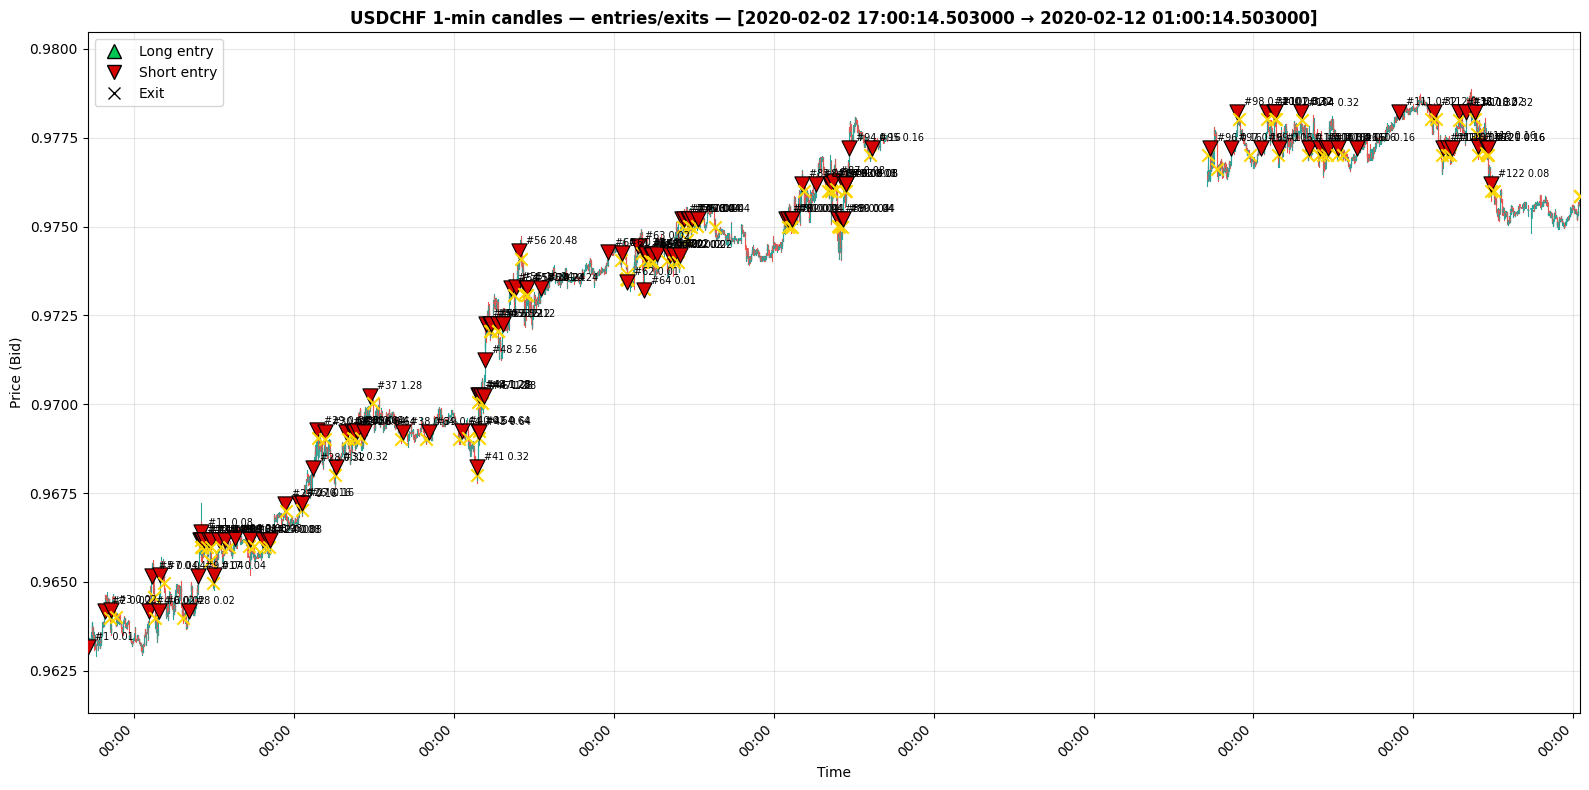

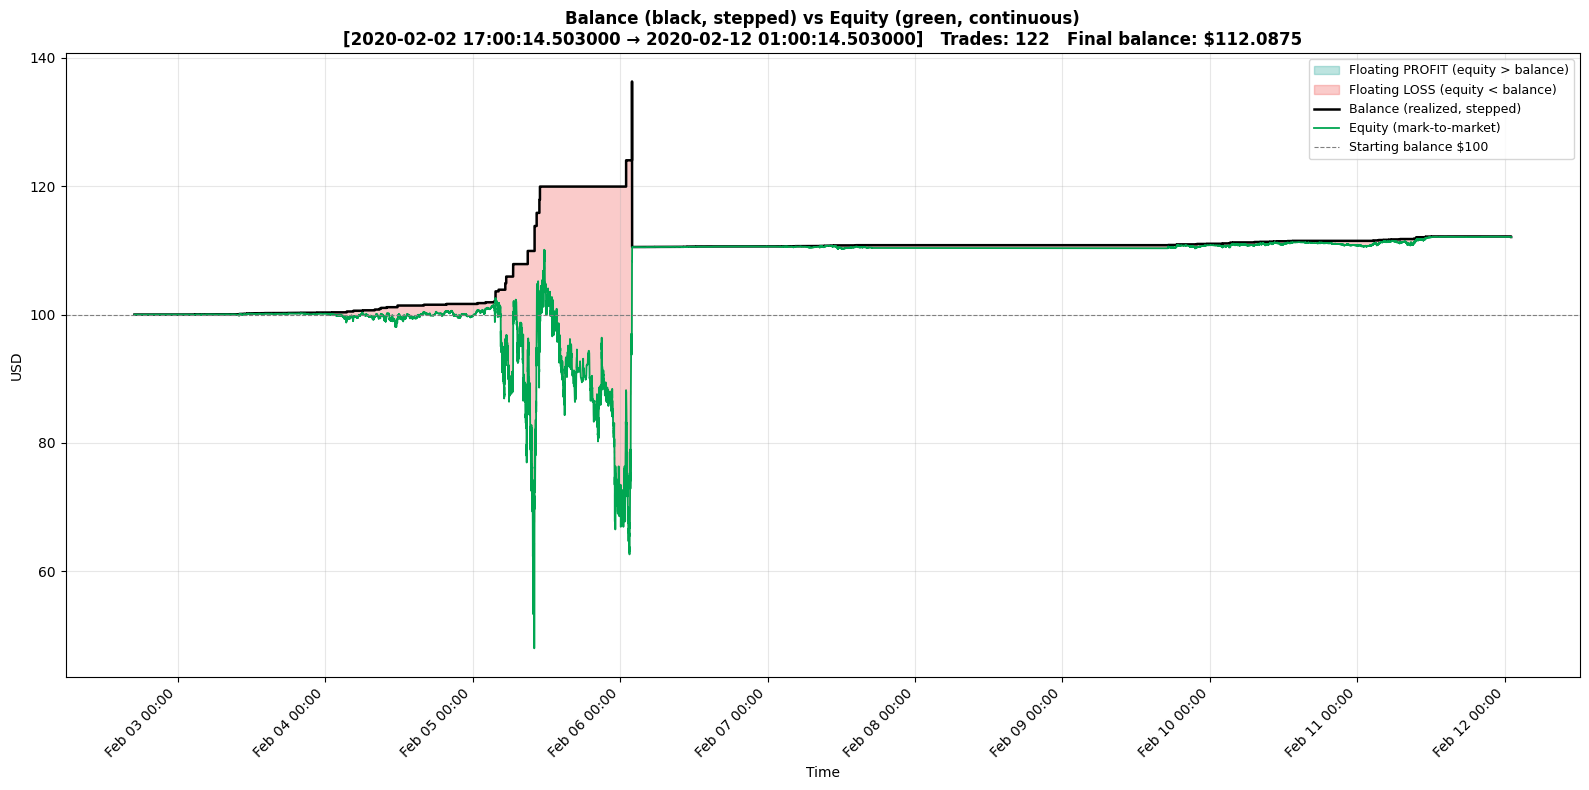

In [3]:
# ================================================================
# CELL B — RUN + PLOT
# Change N_hours and re-execute this cell.
# ================================================================

cfg = Config(
    N_hours         = 224.0,          # ← change to 2.0, 4.0, 8.0, 24.0, None
    start_hour      = 0.0,
    first_lot       = 0.01,
    distance_pips   = 10.0,
    max_orders      = 100,
    tp_in_money     = 0.004,        # 4 pips = $0.004 USD = 0.4 USC
    lot_multiplier  = 2.0,
    use_trailing    = True,
    tp_start        = 2.0,
    tp_move         = 4.0,
    amount_to_risk  = 100.0,
    profit_to_fix   = 10.0,
    contract_size   = 1_000.0,
    leverage        = 500,
)

print(f"\n=== Building window: start_hour={cfg.start_hour}, N_hours={cfg.N_hours} ===")
bars, candles_win, window_start, window_end = build_window(cfg, tick_df, DATA_START)

if len(bars) < 3:
    print("Not enough bars in window — increase N_hours.")
else:
    res = backtest_ticks(bars, cfg, starting_balance=100.0)

    print("=" * 60)
    print(f"Window            : {window_start} → {window_end}")
    print(f"Starting balance  : $100.0000")
    print(f"Final balance     : ${res.balance:.4f}")
    print(f"Return            : {100*(res.balance/100 - 1):.4f}%")
    print(f"Max drawdown      : {100*res.max_dd:.4f}%")
    print(f"Total trades      : {len(res.trades)}")
    print(f"Risk resets       : {res.resets}")
    print(f"Stop outs         : {res.stop_outs}")
    print("=" * 60)

    # ---- Trade log ----
    if res.trades:
        trades_df = pd.DataFrame([{
            'ticket':     t.ticket,
            'side':       'LONG' if t.side == +1 else 'SHORT',
            'lots':       t.lots,
            'entry_time': t.entry_time,
            'entry_px':   t.entry_px,
            'exit_time':  t.exit_time,
            'exit_px':    t.exit_px,
            'pnl':        t.pnl,
            'reason':     t.reason,
        } for t in res.trades])
        print("\nTRADE LOG:")
        print(trades_df.to_string(index=False,
            formatters={'lots': '{:.2f}'.format,
                        'entry_px': '{:.5f}'.format,
                        'exit_px': '{:.5f}'.format,
                        'pnl': '{:+.6f}'.format}))
    else:
        print("\nNo trades executed in this window.")

    # ---- Hourly progress ----
    hourly_df = pd.DataFrame(res.hourly_records)
    if len(hourly_df) > 0:
        hourly_df['hour'] = pd.to_datetime(hourly_df['hour'])
        hourly_df = hourly_df.set_index('hour')
        print("\n" + "=" * 80)
        print("HOURLY PROGRESS")
        print("=" * 80)
        print(hourly_df.to_string(
            formatters={
                'balance':      '{:.4f}'.format,
                'equity':       '{:.4f}'.format,
                'total_lots':   '{:.2f}'.format,
                'margin_used':  '{:.4f}'.format,
                'drawdown_pct': '{:.3f}%'.format,
            }))

    # ---- Hourly Bid/Ask extremes ----
    mask = (tick_df['DateTime'] >= window_start) & (tick_df['DateTime'] <= window_end)
    ticks_win = tick_df.loc[mask].copy()
    if len(ticks_win) > 0:
        ticks_win['Hour'] = ticks_win['DateTime'].dt.floor('1h')
        ticks_win['Spread_pips'] = (ticks_win['Ask'] - ticks_win['Bid']) / cfg.pip_size
        hourly_ext = ticks_win.groupby('Hour').agg(
            Bid_Open   = ('Bid', 'first'),
            Bid_High   = ('Bid', 'max'),
            Bid_Low    = ('Bid', 'min'),
            Bid_Close  = ('Bid', 'last'),
            Ask_Low    = ('Ask', 'min'),
            Ask_High   = ('Ask', 'max'),
            Spread_med = ('Spread_pips', 'median'),
        )
        hourly_ext['Bid_Range_pips'] = (hourly_ext['Bid_High'] - hourly_ext['Bid_Low']) / cfg.pip_size

        print("\n" + "=" * 100)
        print("HOURLY BID/ASK EXTREMES")
        print("=" * 100)
        print(hourly_ext.to_string(
            formatters={
                'Bid_Open':        '{:.5f}'.format,
                'Bid_High':        '{:.5f}'.format,
                'Bid_Low':         '{:.5f}'.format,
                'Bid_Close':       '{:.5f}'.format,
                'Ask_Low':         '{:.5f}'.format,
                'Ask_High':        '{:.5f}'.format,
                'Spread_med':      '{:.2f}'.format,
                'Bid_Range_pips':  '{:.1f}'.format,
            }))

    # ================================================================
    # CANDLE CHART WITH ENTRY/EXIT MARKERS
    # ================================================================
    if candles_win is not None and len(candles_win) > 0:
        fig, ax = plt.subplots(figsize=(16, 8))
        candle_width_sec = 55
        for idx, row in candles_win.iterrows():
            t = row['Minute']
            o, h, l, c = row['Bid_Open'], row['Bid_High'], row['Bid_Low'], row['Bid_Close']
            color = '#26a69a' if c >= o else '#ef5350'
            ax.plot([t, t], [l, h], color=color, linewidth=0.8, zorder=2)
            width = pd.Timedelta(seconds=candle_width_sec)
            body_lo = min(o, c)
            body_hi = max(o, c)
            if body_hi == body_lo:
                body_hi = body_lo + 0.00001
            ax.add_patch(Rectangle(
                (mdates.date2num(t - width/2), body_lo),
                mdates.date2num(t + width/2) - mdates.date2num(t - width/2),
                body_hi - body_lo,
                facecolor=color, edgecolor=color, linewidth=0.5, zorder=3
            ))

        if res.trades:
            for t in res.trades:
                if t.entry_time is None or t.exit_time is None:
                    continue
                marker_side = '^' if t.side == +1 else 'v'
                marker_color = '#00c853' if t.side == +1 else '#d50000'
                ax.scatter(t.entry_time, t.entry_px,
                           marker=marker_side, s=120, color=marker_color,
                           edgecolors='black', linewidths=0.8, zorder=5)
                ax.scatter(t.exit_time, t.exit_px,
                           marker='x', s=80, color='gold',
                           linewidths=1.5, zorder=5)
                ax.annotate(f"#{t.ticket} {t.lots:.2f}",
                            (t.entry_time, t.entry_px),
                            xytext=(5, 5), textcoords='offset points',
                            fontsize=7, color='black', zorder=6)

        y_lo = candles_win['Bid_Low'].min()
        y_hi = candles_win['Bid_High'].max()
        if res.trades:
            valid = [(t.entry_px, t.exit_px) for t in res.trades
                     if t.entry_time and t.exit_time]
            if valid:
                y_lo = min(y_lo, min(min(a, b) for a, b in valid))
                y_hi = max(y_hi, max(max(a, b) for a, b in valid))
        pad = max((y_hi - y_lo) * 0.10, 0.0002)
        ax.set_ylim(y_lo - pad, y_hi + pad)
        ax.set_xlim(candles_win['Minute'].min() - pd.Timedelta(minutes=1),
                    candles_win['Minute'].max() + pd.Timedelta(minutes=1))

        ax.set_xlabel('Time')
        ax.set_ylabel('Price (Bid)')
        ax.set_title(f'USDCHF 1-min candles — entries/exits — [{window_start} → {window_end}]',
                     fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.xaxis.set_major_locator(mdates.AutoDateLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

        legend_elems = [
            Line2D([0], [0], marker='^', color='w', markerfacecolor='#00c853',
                   markersize=10, markeredgecolor='black', label='Long entry'),
            Line2D([0], [0], marker='v', color='w', markerfacecolor='#d50000',
                   markersize=10, markeredgecolor='black', label='Short entry'),
            Line2D([0], [0], marker='x', color='gold', markersize=9,
                   markeredgecolor='black', linewidth=0, label='Exit'),
        ]
        ax.legend(handles=legend_elems, loc='best')
        plt.tight_layout()
        plt.show()

    # ================================================================
    # BALANCE (black, stepped) vs EQUITY (green, continuous) OVERLAY
    # ================================================================
    if len(res.equity) > 1:
        eq = np.array(res.equity)
        times = pd.to_datetime(res.equity_times)

        # Downsample to keep the plot fast
        target = 30_000
        if len(eq) > target:
            idx = np.linspace(0, len(eq) - 1, target).astype(int)
            eq_ds    = eq[idx]
            times_ds = times[idx]
        else:
            eq_ds    = eq
            times_ds = times

        # --- Reconstruct balance at each equity timestamp ---
        starting_balance = 100.0
        close_events = []          # list of (exit_time, balance_after)
        running_bal = starting_balance
        for t in res.trades:
            running_bal += t.pnl
            close_events.append((pd.to_datetime(t.exit_time), running_bal))

        if close_events:
            close_times_arr, close_bals_arr = zip(*close_events)
            close_times_arr = np.array(close_times_arr)
            close_bals_arr  = np.array(close_bals_arr)

            # For each equity timestamp, balance = last close_bal whose time <= t
            pos = np.searchsorted(close_times_arr, times_ds, side='right') - 1
            balance_series = np.where(
                pos >= 0,
                close_bals_arr[np.clip(pos, 0, len(close_bals_arr) - 1)],
                starting_balance,
            )
        else:
            balance_series = np.full_like(eq_ds, starting_balance)

        diff  = eq_ds - balance_series
        above = diff >= 0     # equity above balance → floating profit
        below = diff <  0     # equity below balance → floating loss

        fig, ax = plt.subplots(figsize=(16, 8))

        # Fill regions between the two curves
        ax.fill_between(times_ds, balance_series, eq_ds,
                        where=above, color='#26a69a', alpha=0.30,
                        interpolate=True,
                        label='Floating PROFIT (equity > balance)')
        ax.fill_between(times_ds, balance_series, eq_ds,
                        where=below, color='#ef5350', alpha=0.30,
                        interpolate=True,
                        label='Floating LOSS (equity < balance)')

        # Balance (black stepped)
        ax.step(times_ds, balance_series, where='post',
                color='black', linewidth=1.8, label='Balance (realized, stepped)')

        # Equity (green continuous)
        ax.plot(times_ds, eq_ds,
                color='#00a651', linewidth=1.3, label='Equity (mark-to-market)')

        # Starting balance reference
        ax.axhline(starting_balance, color='gray', linestyle='--',
                   linewidth=0.8, label=f'Starting balance ${starting_balance:.0f}')

        ax.set_xlabel('Time')
        ax.set_ylabel('USD')
        ax.set_title(
            f'Balance (black, stepped) vs Equity (green, continuous)\n'
            f'[{window_start} → {window_end}]   '
            f'Trades: {len(res.trades)}   '
            f'Final balance: ${res.balance:.4f}',
            fontsize=12, fontweight='bold'
        )
        ax.grid(True, alpha=0.3)
        ax.legend(loc='best', fontsize=9)
        ax.xaxis.set_major_locator(mdates.AutoDateLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d %H:%M'))
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

        plt.tight_layout()
        plt.show()

In [6]:
# ================================================================
# CELL C — DYNAMIC ANIMATION (incremental hourly build-up)
#           + EXCEL EXPORT
# Run after Cell A. Independent from Cell B.
# ================================================================

import os
import matplotlib.animation as animation
from matplotlib.lines import Line2D
from matplotlib.dates import MonthLocator, DayLocator, DateFormatter
from openpyxl import Workbook
from openpyxl.utils.dataframe import dataframe_to_rows

# ----------------------------------------------------------------
# 0) CONFIG — reuse the same params as Cell B
# ----------------------------------------------------------------
ANIM_CFG = Config(
    N_hours         = 520.0,          # ← total hours to animate up to
    start_hour      = 0.0,
    first_lot       = 0.01,
    distance_pips   = 10.0,
    max_orders      = 100,
    tp_in_money     = 0.005,          # Note: v2 uses 0.004
    lot_multiplier  = 2.0,
    use_trailing    = True,
    tp_start        = 2.0,
    tp_move         = 4.0,
    amount_to_risk  = 100.0,
    profit_to_fix   = 100.0,
    contract_size   = 1_000.0,
    leverage        = 500,
)

STEP_HOURS   = 1.0                  # grow by 1h each frame
START_BAL    = 100.0
OUT_DIR      = r"D:\grid_ticks_v2"
os.makedirs(OUT_DIR, exist_ok=True)

# ----------------------------------------------------------------
# 1) Build a SINGLE big window once (full N_hours)
#    We'll slice it per-frame to avoid re-parsing ticks.
# ----------------------------------------------------------------
total_hours = ANIM_CFG.N_hours if ANIM_CFG.N_hours is not None else 24.0

print(f"\n=== Building full window for animation: {total_hours} hours ===")
full_cfg = Config(**{**ANIM_CFG.__dict__, "N_hours": total_hours})
bars_full, candles_full, win_start, win_end = build_window(full_cfg, tick_df, DATA_START)

# ---- SANITY PRINTS (added: verify the window before plotting) ----
print(f"   DATA_START  : {DATA_START}")
print(f"   win_start   : {win_start}")
print(f"   win_end     : {win_end}")

# Pre-compute cumulative hour boundaries (in wall-clock time)
hour_marks = [win_start + pd.Timedelta(hours=h)
              for h in np.arange(0, total_hours + STEP_HOURS, STEP_HOURS)]

# ----------------------------------------------------------------
# 2) Incremental backtest
# ----------------------------------------------------------------
print(f"\n=== Running full backtest ({total_hours}h) once ===")
res_full = backtest_ticks(bars_full, ANIM_CFG, starting_balance=START_BAL)
print(f"   Trades: {len(res_full.trades)}, final balance: ${res_full.balance:.4f}")

# ---- SANITY PRINTS (added: check the equity series span) ----
print(f"   eq_times[0] : {res_full.equity_times[0]}")
print(f"   eq_times[-1]: {res_full.equity_times[-1]}")

# Reconstruct balance timeline (realized balance after each close)
close_events = []
running_bal = START_BAL
for t in res_full.trades:
    running_bal += t.pnl
    close_events.append((pd.to_datetime(t.exit_time), running_bal))

eq_times = pd.to_datetime(res_full.equity_times)
eq_vals  = np.array(res_full.equity)

if close_events:
    close_times_arr = np.array([e[0] for e in close_events])
    close_bals_arr  = np.array([e[1] for e in close_events])
    pos = np.searchsorted(close_times_arr, eq_times, side='right') - 1
    bal_vals = np.where(
        pos >= 0,
        close_bals_arr[np.clip(pos, 0, len(close_bals_arr) - 1)],
        START_BAL,
    )
else:
    bal_vals = np.full_like(eq_vals, START_BAL)

# ----------------------------------------------------------------
# 3) Build per-frame slices
# ----------------------------------------------------------------
frame_data = []
for hm in hour_marks:
    mask = eq_times <= hm
    if mask.sum() < 2:
        continue
    frame_data.append({
        "hour_mark": hm,
        "times":     eq_times[mask],
        "equity":    eq_vals[mask],
        "balance":   bal_vals[mask],
    })

print(f"   Frames prepared: {len(frame_data)}")

if len(frame_data) < 2:
    print("Not enough frames — increase N_hours or STEP_HOURS.")
else:
    # ----------------------------------------------------------------
    # 4) Animate
    # ----------------------------------------------------------------
    y_all = np.concatenate([fd["equity"] for fd in frame_data] +
                           [fd["balance"] for fd in frame_data])
    y_lo = min(y_all.min(), START_BAL) - 0.5
    y_hi = max(y_all.max(), START_BAL) + 0.5

    fig, ax = plt.subplots(figsize=(14, 7))

    ln_bal, = ax.plot([], [], color='black', linewidth=1.8, label='Balance (realized)')
    ln_eq,  = ax.plot([], [], color='#00a651', linewidth=1.4, label='Equity (mark-to-market)')
    ax.axhline(START_BAL, color='gray', linestyle='--', linewidth=0.8,
               label=f'Starting balance ${START_BAL:.0f}')

    title_txt = ax.set_title("", fontsize=12, fontweight='bold')
    ax.set_xlabel('Time')
    ax.set_ylabel('USD')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=9)

    # ================================================================
    ### PATCHED: X-axis date enforcement ###
    # ================================================================
    # Derive the true date range from the equity series itself,
    # not from frame_data (which is only what's *been shown so far*).
    # This is what guarantees the axis reflects the actual data span.
    x_lo = pd.to_datetime(eq_times[0])
    x_hi = pd.to_datetime(eq_times[-1])

    print(f"   X-axis pinned: {x_lo}  →  {x_hi}")

    ax.set_xlim(x_lo, x_hi)

    # Force month ticks + day subticks. No stray labels from other years.
    ax.xaxis.set_major_locator(MonthLocator())
    ax.xaxis.set_major_formatter(DateFormatter('%b %Y'))
    ax.xaxis.set_minor_locator(DayLocator(interval=7))
    ax.xaxis.set_minor_formatter(DateFormatter('%d'))

    # Bigger month labels, smaller day labels
    ax.tick_params(axis='x', which='major', labelsize=10, pad=12)
    ax.tick_params(axis='x', which='minor', labelsize=7,  pad=2)
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=0,  ha='center')
    plt.setp(ax.xaxis.get_minorticklabels(), rotation=45, ha='right')

    ax.set_ylim(y_lo, y_hi)
    # ================================================================

    def init():
        ln_bal.set_data([], [])
        ln_eq.set_data([], [])
        return ln_bal, ln_eq, title_txt

    def update(k):
        fd = frame_data[k]
        t_arr = mdates.date2num(fd["times"])
        ln_bal.set_data(t_arr, fd["balance"])
        ln_eq.set_data(t_arr,  fd["equity"])
        eq_now = fd["equity"][-1]
        bal_now = fd["balance"][-1]
        hours_now = (fd["hour_mark"] - win_start).total_seconds() / 3600.0
        title_txt.set_text(
            f"USDCHF v2 (No Markup)  —  Hour {hours_now:.0f} / {total_hours:.0f}\n"
            f"Equity: ${eq_now:.4f}    Balance: ${bal_now:.4f}    "
            f"Floating: ${eq_now - bal_now:+.4f}"
        )
        return ln_bal, ln_eq, title_txt

    ani = animation.FuncAnimation(
        fig, update, frames=len(frame_data),
        init_func=init, blit=False, interval=200, repeat=False,
    )

    # ---- Save MP4 (needs ffmpeg) and GIF ----
    mp4_path = os.path.join(OUT_DIR, "grid_balance_equity_v2.mp4")
    gif_path = os.path.join(OUT_DIR, "grid_balance_equity_v2.gif")

    try:
        ani.save(mp4_path, writer='ffmpeg', fps=5, dpi=110)
        print(f"   MP4 saved → {mp4_path}")
    except Exception as e:
        print(f"   MP4 save failed ({e}); trying GIF only.")

    try:
        ani.save(gif_path, writer='pillow', fps=5, dpi=90)
        print(f"   GIF saved → {gif_path}")
    except Exception as e:
        print(f"   GIF save failed: {e}")

    plt.close(fig)

    # ----------------------------------------------------------------
    # 5) Excel export — all trades + hourly snapshots
    # ----------------------------------------------------------------
    xlsx_path = os.path.join(OUT_DIR, "grid_trades_v2.xlsx")

    trades_df = pd.DataFrame([{
        'ticket':     t.ticket,
        'side':       'LONG' if t.side == +1 else 'SHORT',
        'lots':       t.lots,
        'entry_time': t.entry_time,
        'entry_px':   t.entry_px,
        'exit_time':  t.exit_time,
        'exit_px':    t.exit_px,
        'pnl':        t.pnl,
        'reason':     t.reason,
    } for t in res_full.trades])

    hourly_df = pd.DataFrame(res_full.hourly_records)

    summary_df = pd.DataFrame([
        ("Starting balance",  START_BAL),
        ("Final balance",     res_full.balance),
        ("Return %",          100 * (res_full.balance / START_BAL - 1)),
        ("Max drawdown %",    100 * res_full.max_dd),
        ("Total trades",      len(res_full.trades)),
        ("Risk resets",       res_full.resets),
        ("Stop outs",         res_full.stop_outs),
        ("Window start",      str(win_start)),
        ("Window end",        str(win_end)),
        ("Total hours",       total_hours),
    ], columns=["Metric", "Value"])

    try:
        with pd.ExcelWriter(xlsx_path, engine='openpyxl') as xw:
            summary_df.to_excel(xw, sheet_name='Summary',  index=False)
            trades_df.to_excel (xw, sheet_name='Trades',   index=False)
            if len(hourly_df) > 0:
                hourly_df.to_excel(xw, sheet_name='Hourly', index=False)
        print(f"   Excel saved → {xlsx_path}")
        print(f"   Trades: {len(trades_df)} rows | Hourly: {len(hourly_df)} rows")
    except PermissionError:
        print(f"\n   [ERROR] Could not save Excel file: Permission denied for {xlsx_path}")
        print("   Please close the file if it is open in another program and try again.")


print("\n=== Cell C complete ===")


=== Building full window for animation: 520.0 hours ===


C:\Users\user\AppData\Local\Temp\ipykernel_8372\436554302.py:461: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  candles_win = ticks_win.groupby('Minute').apply(compute_ohlc_with_spread).reset_index()


   Ticks in window : 775,368
   Candles built   : 22,413
   Build time      : 34.16s
   DATA_START  : 2020-02-02 17:00:14.503000
   win_start   : 2020-02-02 17:00:14.503000
   win_end     : 2020-02-24 09:00:14.503000

=== Running full backtest (520.0h) once ===
   Trades: 264, final balance: $293.1203
   eq_times[0] : 2020-02-02 17:00:00
   eq_times[-1]: 2020-02-24 09:00:14.413000
   Frames prepared: 520
   X-axis pinned: 2020-02-02 17:00:00  →  2020-02-24 09:00:14.413000
   MP4 saved → D:\grid_ticks_v2\grid_balance_equity_v2.mp4
   GIF saved → D:\grid_ticks_v2\grid_balance_equity_v2.gif
   Excel saved → D:\grid_ticks_v2\grid_trades_v2.xlsx
   Trades: 264 rows | Hourly: 377 rows

=== Cell C complete ===
